# 05_SHAP_XGBoost — Explain the Final XGBoost Model

**Project:** Remaining Useful Life Prediction for Turbofan Engines Using XGBoost and LSTM  
**Dataset:** NASA C-MAPSS FD001

This notebook adds a small SHAP analysis to the final XGBoost model.

The purpose is simple:

- load the XGBoost model that was already trained
- rebuild the same 93 input features
- explain the final prediction for each of the 100 test engines
- find which features had the largest overall effect
- save a SHAP bar plot and summary plot

This notebook does **not** train a new model and does not change the final XGBoost result.


## 1. Imports

This notebook needs the `shap` package.

If the next cell says SHAP is not installed, run this in a new Jupyter cell:

```python
%pip install shap
```

Then restart the kernel and run the notebook again.


In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import shap
except ImportError as exc:
    raise ImportError(
        "SHAP is not installed. Run `%pip install shap`, "
        "restart the kernel, and run all cells again."
    ) from exc

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


## 2. Settings

I use the same RUL cap and rolling windows as the final XGBoost notebook.


In [2]:
RUL_CAP = 125
ROLL_WINDOWS = (5, 10)

XGB_DIR = Path("xgboost_outputs")
OUTPUT_DIR = Path("shap_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

MODEL_PATH = XGB_DIR / "xgboost_fd001_model.joblib"

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        "The saved XGBoost model was not found. "
        "Run 02_XGBoost_FINAL.ipynb first."
    )

print("Model file:", MODEL_PATH)
print("Output folder:", OUTPUT_DIR.resolve())

Model file: xgboost_outputs\xgboost_fd001_model.joblib
Output folder: C:\Users\ak587\Downloads\New folder\shap_outputs


## 3. Load FD001

The same three FD001 files used in the earlier notebooks are loaded here.


In [3]:
def resolve_file(filename):
    local = Path(filename)
    if local.exists():
        return local

    alt = Path("/mnt/data") / filename
    if alt.exists():
        return alt

    raise FileNotFoundError(
        f"{filename} was not found. Put it in the same folder as this notebook."
    )


TRAIN_PATH = resolve_file("train_FD001.txt")
TEST_PATH = resolve_file("test_FD001.txt")
RUL_PATH = resolve_file("RUL_FD001.txt")

columns = (
    ["unit", "cycle"]
    + [f"op_setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

train = pd.read_csv(
    TRAIN_PATH,
    sep=r"\s+",
    header=None,
    names=columns
)

test = pd.read_csv(
    TEST_PATH,
    sep=r"\s+",
    header=None,
    names=columns
)

test_rul = pd.read_csv(
    RUL_PATH,
    sep=r"\s+",
    header=None,
    names=["RUL"]
)

print("Training shape:", train.shape)
print("Test shape:", test.shape)
print("RUL shape:", test_rul.shape)

Training shape: (20631, 26)
Test shape: (13096, 26)
RUL shape: (100, 1)


## 4. Rebuild the same XGBoost features

The final XGBoost model used the non-constant sensors together with current values, first differences, and rolling statistics over 5 and 10 cycles.

Only the current and earlier cycles are used when making the rolling features.


In [4]:
train_model = train.copy()

max_cycle_per_engine = (
    train_model.groupby("unit")["cycle"]
    .transform("max")
)

train_model["RUL_raw"] = (
    max_cycle_per_engine - train_model["cycle"]
)

train_model["RUL"] = (
    train_model["RUL_raw"]
    .clip(upper=RUL_CAP)
)

constant_columns = [
    col for col in columns
    if train_model[col].nunique(dropna=False) == 1
]

sensor_columns = [
    f"sensor_{i}" for i in range(1, 22)
]

informative_sensors = [
    col for col in sensor_columns
    if col not in constant_columns
]

print("Constant columns:", constant_columns)
print("Informative sensors:", len(informative_sensors))

Constant columns: ['op_setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Informative sensors: 15


In [5]:
def add_temporal_features(
    df,
    sensor_cols,
    windows=(5, 10)
):
    result = (
        df.sort_values(["unit", "cycle"])
        .copy()
    )

    grouped = result.groupby(
        "unit",
        group_keys=False
    )

    for sensor in sensor_cols:
        result[f"{sensor}_diff1"] = (
            grouped[sensor]
            .diff()
            .fillna(0.0)
        )

        for w in windows:
            result[f"{sensor}_rollmean_{w}"] = (
                grouped[sensor]
                .rolling(
                    window=w,
                    min_periods=1
                )
                .mean()
                .reset_index(
                    level=0,
                    drop=True
                )
            )

            result[f"{sensor}_rollstd_{w}"] = (
                grouped[sensor]
                .rolling(
                    window=w,
                    min_periods=2
                )
                .std()
                .reset_index(
                    level=0,
                    drop=True
                )
                .fillna(0.0)
            )

    return result


test_feat = add_temporal_features(
    test,
    informative_sensors,
    windows=ROLL_WINDOWS
)

base_feature_columns = (
    [
        "cycle",
        "op_setting_1",
        "op_setting_2"
    ]
    + informative_sensors
)

temporal_feature_columns = []

for sensor in informative_sensors:
    temporal_feature_columns.append(
        f"{sensor}_diff1"
    )

    for w in ROLL_WINDOWS:
        temporal_feature_columns.append(
            f"{sensor}_rollmean_{w}"
        )

        temporal_feature_columns.append(
            f"{sensor}_rollstd_{w}"
        )

feature_columns = (
    base_feature_columns
    + temporal_feature_columns
)

print("Feature count:", len(feature_columns))
print("Test feature table:", test_feat.shape)

assert len(feature_columns) == 93

Feature count: 93
Test feature table: (13096, 101)


## 5. Use one row for each test engine

The official XGBoost prediction uses the final observed row for each test engine.

I use those same 100 rows for SHAP so the explanation matches the final test predictions.


In [6]:
test_last = (
    test_feat
    .sort_values(["unit", "cycle"])
    .groupby("unit", as_index=False)
    .tail(1)
    .sort_values("unit")
    .reset_index(drop=True)
)

X_explain = (
    test_last[feature_columns]
    .copy()
)

actual_rul = (
    test_rul["RUL"]
    .to_numpy(dtype=float)
)

print("Engines explained:", len(X_explain))
print("Feature count:", X_explain.shape[1])

assert X_explain.shape == (100, 93)

Engines explained: 100
Feature count: 93


## 6. Load the saved XGBoost model

This is the exact model saved by the final XGBoost notebook.


In [7]:
model = joblib.load(MODEL_PATH)

predictions = model.predict(X_explain)

print("Loaded model:", type(model).__name__)
print("Predictions:", len(predictions))
print(
    "First five predictions:",
    np.round(predictions[:5], 2)
)

Loaded model: XGBRegressor
Predictions: 100
First five predictions: [122.9  121.14  54.79  81.62  94.92]


## 7. Calculate SHAP values

SHAP gives a contribution value for every input feature and every test engine.

A positive SHAP value pushes the predicted RUL upward. A negative value pushes it downward relative to the model's baseline prediction.


In [8]:
explainer = shap.TreeExplainer(model)

shap_values = explainer.shap_values(
    X_explain
)

shap_values = np.asarray(shap_values)

print("SHAP value shape:", shap_values.shape)

assert shap_values.shape == X_explain.shape

SHAP value shape: (100, 93)


## 8. Overall SHAP importance

For each feature, I calculate the mean absolute SHAP value across the 100 test engines.

A larger value means the feature had a larger average effect on the final XGBoost predictions.


In [9]:
mean_abs_shap = np.abs(
    shap_values
).mean(axis=0)

shap_importance = pd.DataFrame({
    "feature": feature_columns,
    "mean_absolute_SHAP": mean_abs_shap
})

shap_importance = (
    shap_importance
    .sort_values(
        "mean_absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

display(shap_importance.head(20))

shap_importance.to_csv(
    OUTPUT_DIR / "shap_feature_importance.csv",
    index=False
)

print("\nTop five SHAP features:")

for i, row in shap_importance.head(5).iterrows():
    print(
        f"{i + 1}. {row['feature']}: "
        f"{row['mean_absolute_SHAP']:.4f}"
    )

,feature,mean_absolute_SHAP
0,cycle,9.729001
1,sensor_11_rollmean_5,4.317716
2,sensor_15_rollmean_10,4.218518
3,sensor_2_rollmean_10,3.643804
4,sensor_4_rollmean_5,3.481027
5,sensor_4_rollmean_10,2.393983
6,sensor_3_rollmean_10,2.317061
7,sensor_15_rollmean_5,2.050733
8,sensor_9_rollmean_5,1.729009
9,sensor_14_rollmean_10,1.614848



Top five SHAP features:
1. cycle: 9.7290
2. sensor_11_rollmean_5: 4.3177
3. sensor_15_rollmean_10: 4.2185
4. sensor_2_rollmean_10: 3.6438
5. sensor_4_rollmean_5: 3.4810


## 9. SHAP importance bar plot

This plot shows the features with the largest average effect on the XGBoost predictions.


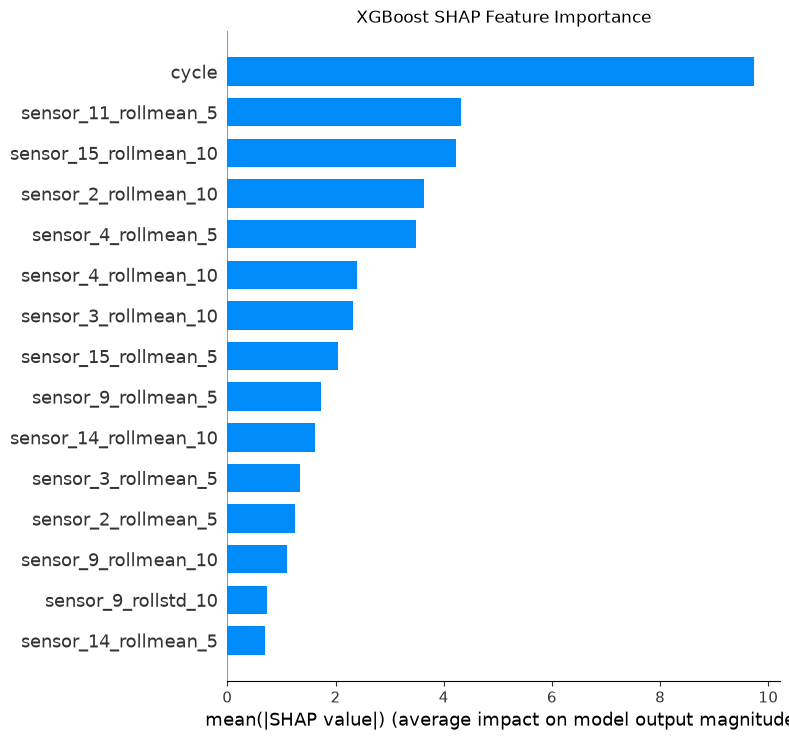

In [10]:
plt.figure()

shap.summary_plot(
    shap_values,
    X_explain,
    plot_type="bar",
    max_display=15,
    show=False
)

plt.title(
    "XGBoost SHAP Feature Importance"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "shap_feature_importance.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 10. SHAP summary plot

This plot also shows the direction of each feature's effect.

Each point represents one test engine. The horizontal position shows whether the feature pushed the RUL prediction higher or lower.


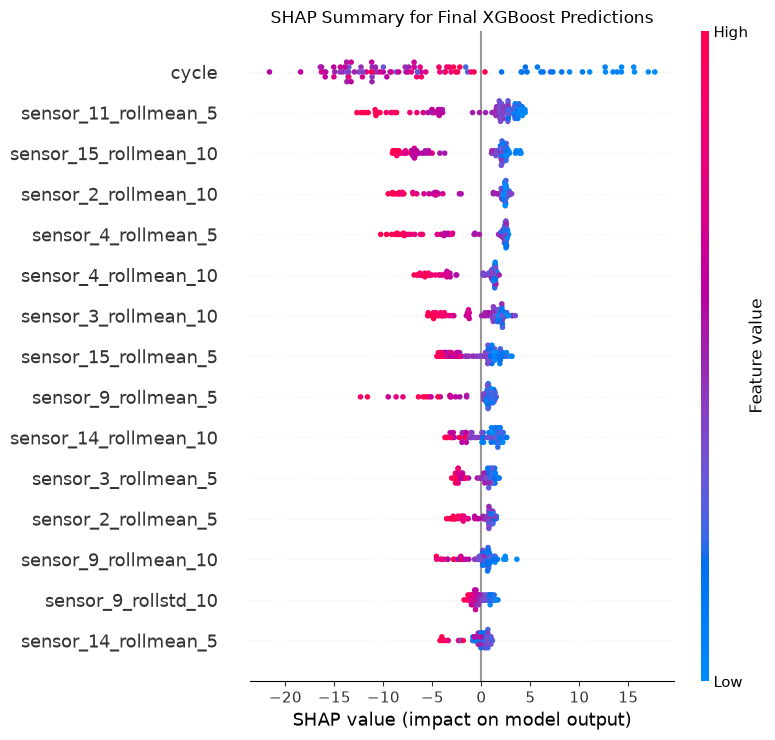

In [11]:
plt.figure()

shap.summary_plot(
    shap_values,
    X_explain,
    max_display=15,
    show=False
)

plt.title(
    "SHAP Summary for Final XGBoost Predictions"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "shap_summary_plot.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 11. Explain one test engine

This example explains the engine with the largest XGBoost absolute error.

It is useful because it shows which features pushed that difficult prediction up or down.


In [12]:
absolute_errors = np.abs(
    predictions - actual_rul
)

worst_index = int(
    np.argmax(absolute_errors)
)

worst_unit = int(
    test_last.loc[
        worst_index,
        "unit"
    ]
)

print("Engine:", worst_unit)
print(
    "Actual RUL:",
    actual_rul[worst_index]
)
print(
    "Predicted RUL:",
    round(
        float(predictions[worst_index]),
        2
    )
)
print(
    "Absolute error:",
    round(
        float(absolute_errors[worst_index]),
        2
    )
)

local_contributions = pd.DataFrame({
    "feature": feature_columns,
    "feature_value": (
        X_explain
        .iloc[worst_index]
        .to_numpy()
    ),
    "SHAP_value": (
        shap_values[worst_index]
    )
})

local_contributions["absolute_SHAP"] = (
    local_contributions["SHAP_value"]
    .abs()
)

local_contributions = (
    local_contributions
    .sort_values(
        "absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

display(local_contributions.head(15))

local_contributions.to_csv(
    OUTPUT_DIR
    / f"engine_{worst_unit}_shap_contributions.csv",
    index=False
)

Engine: 45
Actual RUL: 114.0
Predicted RUL: 59.89
Absolute error: 54.11


,feature,feature_value,SHAP_value,absolute_SHAP
0,cycle,152.000000,-11.194753,11.194753
1,sensor_15_rollmean_10,8.458980,-6.802253,6.802253
2,sensor_2_rollmean_10,642.920000,-4.769200,4.769200
3,sensor_4_rollmean_10,1413.318000,-3.522839,3.522839
4,sensor_15_rollmean_5,8.468880,-3.205629,3.205629
5,sensor_14_rollmean_10,8139.139000,1.875157,1.875157
6,sensor_3_rollmean_5,1594.946000,-1.800293,1.800293
7,sensor_11_rollmean_5,47.620000,1.498044,1.498044
8,sensor_3_rollmean_10,1593.630000,-1.415644,1.415644
9,sensor_2_rollmean_5,642.886000,1.181782,1.181782


## 12. Local SHAP waterfall plot

The waterfall plot shows how individual features moved the prediction away from the model's average prediction for the selected engine.


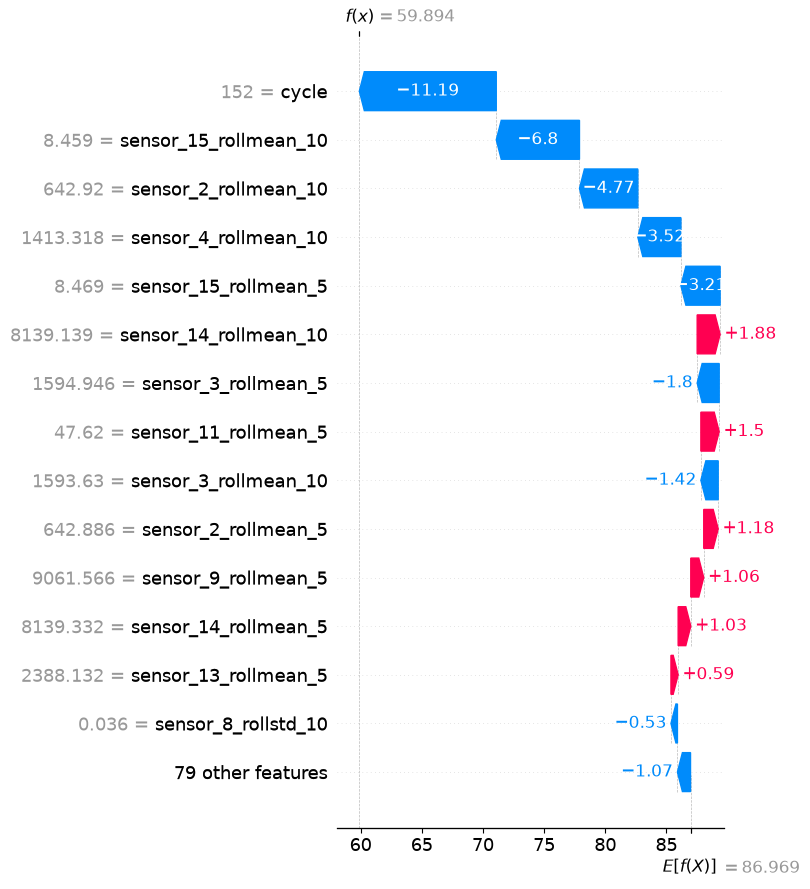

In [13]:
base_value = explainer.expected_value

if isinstance(
    base_value,
    (list, np.ndarray)
):
    base_value = np.asarray(
        base_value
    ).reshape(-1)[0]

explanation = shap.Explanation(
    values=shap_values[worst_index],
    base_values=float(base_value),
    data=(
        X_explain
        .iloc[worst_index]
        .to_numpy()
    ),
    feature_names=feature_columns
)

shap.plots.waterfall(
    explanation,
    max_display=15,
    show=False
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR
    / f"engine_{worst_unit}_shap_waterfall.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 13. Compare SHAP with XGBoost built-in importance

The final XGBoost notebook already reported built-in feature importance.

SHAP is different because it measures how much each feature actually changed the model predictions across the selected test engines.

The two rankings do not have to be identical.


In [14]:
builtin_importance = pd.DataFrame({
    "feature": feature_columns,
    "xgboost_importance": (
        model.feature_importances_
    )
})

builtin_importance = (
    builtin_importance
    .sort_values(
        "xgboost_importance",
        ascending=False
    )
    .reset_index(drop=True)
)

comparison = (
    shap_importance
    .merge(
        builtin_importance,
        on="feature",
        how="left"
    )
)

display(comparison.head(20))

comparison.to_csv(
    OUTPUT_DIR
    / "shap_vs_xgboost_importance.csv",
    index=False
)

,feature,mean_absolute_SHAP,xgboost_importance
0,cycle,9.729001,0.014413
1,sensor_11_rollmean_5,4.317716,0.091266
2,sensor_15_rollmean_10,4.218518,0.133012
3,sensor_2_rollmean_10,3.643804,0.094482
4,sensor_4_rollmean_5,3.481027,0.240414
5,sensor_4_rollmean_10,2.393983,0.123737
6,sensor_3_rollmean_10,2.317061,0.033348
7,sensor_15_rollmean_5,2.050733,0.025624
8,sensor_9_rollmean_5,1.729009,0.018642
9,sensor_14_rollmean_10,1.614848,0.003576


## 14. Save a short summary

This file stores the main SHAP results so they can be used later in the dissertation.


In [15]:
top_10 = shap_importance.head(10)

summary = {
    "engines_explained": int(
        len(X_explain)
    ),
    "feature_count": int(
        len(feature_columns)
    ),
    "top_10_features": [
        {
            "feature": str(row["feature"]),
            "mean_absolute_SHAP": float(
                row["mean_absolute_SHAP"]
            )
        }
        for _, row in top_10.iterrows()
    ],
    "example_engine": int(worst_unit),
    "example_actual_RUL": float(
        actual_rul[worst_index]
    ),
    "example_predicted_RUL": float(
        predictions[worst_index]
    ),
    "example_absolute_error": float(
        absolute_errors[worst_index]
    )
}

with open(
    OUTPUT_DIR / "shap_summary.json",
    "w"
) as f:
    json.dump(
        summary,
        f,
        indent=2
    )

print(
    "Saved SHAP outputs to:",
    OUTPUT_DIR.resolve()
)

Saved SHAP outputs to: C:\Users\ak587\Downloads\New folder\shap_outputs


## 15. SHAP project log

### What I checked

I used SHAP to explain the final XGBoost predictions for all **100 FD001 test engines**.

The analysis used the same **93 XGBoost features** as the final model.

### Main SHAP features

The five features with the highest mean absolute SHAP values were:

1. `cycle` — **9.7290**
2. `sensor_11_rollmean_5` — **4.3177**
3. `sensor_15_rollmean_10` — **4.2185**
4. `sensor_2_rollmean_10` — **3.6438**
5. `sensor_4_rollmean_5` — **3.4810**

The result shows that engine age (`cycle`) had the largest overall effect on the XGBoost predictions. Several rolling sensor features were also important, which agrees with the earlier XGBoost feature-importance results.

### Example difficult engine

Engine **45** had the largest XGBoost absolute error in this analysis.

- Actual RUL: **114 cycles**
- Predicted RUL: **59.89 cycles**
- Absolute error: **54.11 cycles**

For this engine, `cycle` and several rolling sensor features had large SHAP contributions.

### Main point

The SHAP analysis gives extra information about how the XGBoost model made its predictions. It supports the finding that recent sensor history was important for the model.

SHAP values explain the model's predictions. They do not prove that a feature causes engine degradation.
